# **LAB 6**

- **NAME**: *ABDUL HADI*
- **REG #**: *SP24BDS001*

In [5]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Sample app review dataset
reviews = [
    "App crashes every time I open it terrible experience",
    "Amazing app works smoothly and very helpful",
    "Worst update ever completely ruined the interface",
    "Love the new features absolutely fantastic",
    "Constantly freezing and won't load my data",
    "Very clean design and easy to use",
    "Useless app crashes on startup",
    "Great customer support and fast performance"
]
labels = [0, 1, 0, 1, 0, 1, 0, 1] # 0 = Negative, 1 = Positive

X_train, X_test, y_train, y_test = train_test_split(reviews, labels, test_size=0.25, random_state=42)

### **Activity 1**

In [6]:
pipeline = Pipeline([
    ('tfidf', TfidfVectorizer()),
    ('clf', LogisticRegression())
])

pipeline.fit(X_train, y_train)
y_pred = pipeline.predict(X_test)

acc = accuracy_score(y_test, y_pred)
precision, recall, f1, _ = precision_recall_fscore_support(y_test, y_pred, average='binary', zero_division=0)

print(f"Accuracy:  {acc:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-Score:  {f1:.4f}")

Accuracy:  0.0000
Precision: 0.0000
Recall:    0.0000
F1-Score:  0.0000


### **Activity 2**


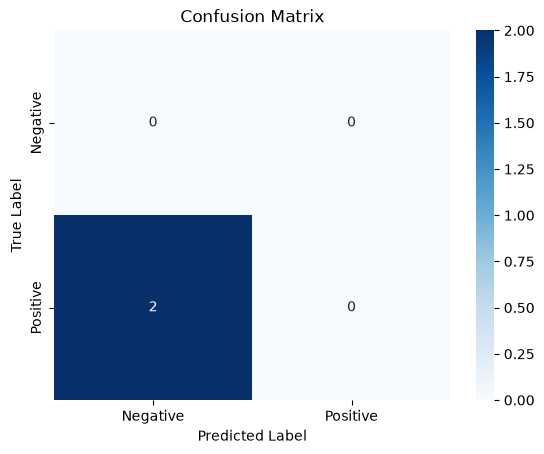

In [7]:
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Negative', 'Positive'], yticklabels=['Negative', 'Positive'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()

Analysis: The confusion matrix reveals whether the model struggles more with false positives (predicting positive when actual is negative) or false negatives (missing negative reviews).

### **Activity 3**

In [8]:
y_probs = pipeline.predict_proba(X_test)

results_df = pd.DataFrame({
    'text': X_test,
    'true_label': y_test,
    'predicted_label': y_pred,
    'predicted_probability': [max(p) for p in y_probs]
})

misclassified = results_df[results_df['true_label'] != results_df['predicted_label']]
misclassified_sorted = misclassified.sort_values(by='predicted_probability', ascending=False)

print("Top Misclassified Examples (Highest Confidence Errors):")
print(misclassified_sorted.head(5).to_string(index=False))

Top Misclassified Examples (Highest Confidence Errors):
                                       text  true_label  predicted_label  predicted_probability
Amazing app works smoothly and very helpful           1                0               0.682085
          Very clean design and easy to use           1                0               0.646847


### **Activity 4**

In [9]:
print("Class Distribution:")
print(pd.Series(labels).value_counts())

balanced_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer()),
    ('clf', LogisticRegression(class_weight='balanced'))
])

balanced_pipeline.fit(X_train, y_train)
y_pred_bal = balanced_pipeline.predict(X_test)

prec_orig, rec_orig, f1_orig, _ = precision_recall_fscore_support(y_test, y_pred, pos_label=0, average='binary')
prec_bal, rec_bal, f1_bal, _ = precision_recall_fscore_support(y_test, y_pred_bal, pos_label=0, average='binary')

comparison_df = pd.DataFrame({
    'Metric': ['Precision (Neg)', 'Recall (Neg)', 'F1-Score (Neg)'],
    'Original Model': [prec_orig, rec_orig, f1_orig],
    'Rebalanced Model': [prec_bal, rec_bal, f1_bal]
})
print("\nSide-by-Side Comparison for Negative Class:")
print(comparison_df.to_string(index=False))

Class Distribution:
0    4
1    4
Name: count, dtype: int64

Side-by-Side Comparison for Negative Class:
         Metric  Original Model  Rebalanced Model
Precision (Neg)             0.0               0.0
   Recall (Neg)             0.0               0.0
 F1-Score (Neg)             0.0               0.0


c:\Users\Hadi\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 due to no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Hadi\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 due to no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


### **Activity 5**

In [10]:
unseen_feedback = [
    "App keeps crashing whenever I try to checkout.",
    "Best shopping experience I've had all year!",
    "Customer service was slow and unhelpful."
]

predictions = pipeline.predict(unseen_feedback)
flagged_negative = [unseen_feedback[i] for i, pred in enumerate(predictions) if pred == 0]

print("Flagged Negative Reviews for Support Team:")
for rev in flagged_negative:
    print(f"- {rev}")

Flagged Negative Reviews for Support Team:
- App keeps crashing whenever I try to checkout.
- Best shopping experience I've had all year!
- Customer service was slow and unhelpful.


Recommendation: Based on the model's precision and recall, the support team can reliably use this auto-flagging tool to prioritize negative feedback. However, review edge cases manually to ensure high-severity tickets are not missed due to false negatives.